In [2]:
import os
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()

print("SSL certificate configured:")
print(certifi.where())

SSL certificate configured:
/Users/keonhowang/Desktop/MedVision/.venv/lib/python3.12/site-packages/certifi/cacert.pem


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from medmnist import PathMNIST, INFO

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Identify the project root directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)

Project directory: /Users/keonhowang/Desktop/MedVision
Dataset directory: /Users/keonhowang/Desktop/MedVision/data/raw


In [5]:
# Download the training dataset
train_dataset = PathMNIST(
    split="train",
    download=True,
    root=str(DATA_DIR)
)

# Download the validation dataset
val_dataset = PathMNIST(
    split="val",
    download=True,
    root=str(DATA_DIR)
)

# Download the testing dataset
test_dataset = PathMNIST(
    split="test",
    download=True,
    root=str(DATA_DIR)
)

print("Dataset downloaded successfully!")

100%|██████████| 206M/206M [05:51<00:00, 585kB/s]  


Dataset downloaded successfully!


In [6]:
print("TRAINING DATASET")
print(train_dataset)

print("\nVALIDATION DATASET")
print(val_dataset)

print("\nTEST DATASET")
print(test_dataset)


TRAINING DATASET
Dataset PathMNIST of size 28 (pathmnist)
    Number of datapoints: 89996
    Root location: /Users/keonhowang/Desktop/MedVision/data/raw
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}
    Number of samples: {'train': 89996, 'val': 10004, 'test': 7180}
    Description: The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×2

In [7]:
# Access the underlying NumPy arrays
images = train_dataset.imgs
labels = train_dataset.labels

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

print("First five labels:")
print(labels[:5])

Image shape: (89996, 28, 28, 3)
Label shape: (89996, 1)
Image data type: uint8
Label data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
First five labels:
[[0]
 [4]
 [7]
 [5]
 [5]]


In [8]:
# Retrieve official label information
info = INFO["pathmnist"]

class_names = {
    int(key): value
    for key, value in info["label"].items()
}

print("Number of classes:", len(class_names))

for label, name in class_names.items():
    print(f"Class {label}: {name}")

Number of classes: 9
Class 0: adipose
Class 1: background
Class 2: debris
Class 3: lymphocytes
Class 4: mucus
Class 5: smooth muscle
Class 6: normal colon mucosa
Class 7: cancer-associated stroma
Class 8: colorectal adenocarcinoma epithelium


In [9]:
# Flatten labels into a one-dimensional array
flat_labels = labels.flatten()

# Count occurrences of each class
class_counts = Counter(flat_labels)

# Create a DataFrame
class_distribution = pd.DataFrame([
    {
        "Class ID": class_id,
        "Category": class_names[class_id],
        "Image Count": class_counts.get(class_id, 0)
    }
    for class_id in class_names
])

print(class_distribution)

   Class ID                              Category  Image Count
0         0                               adipose         9366
1         1                            background         9509
2         2                                debris        10360
3         3                           lymphocytes        10401
4         4                                 mucus         8006
5         5                         smooth muscle        12182
6         6                   normal colon mucosa         7886
7         7              cancer-associated stroma         9401
8         8  colorectal adenocarcinoma epithelium        12885


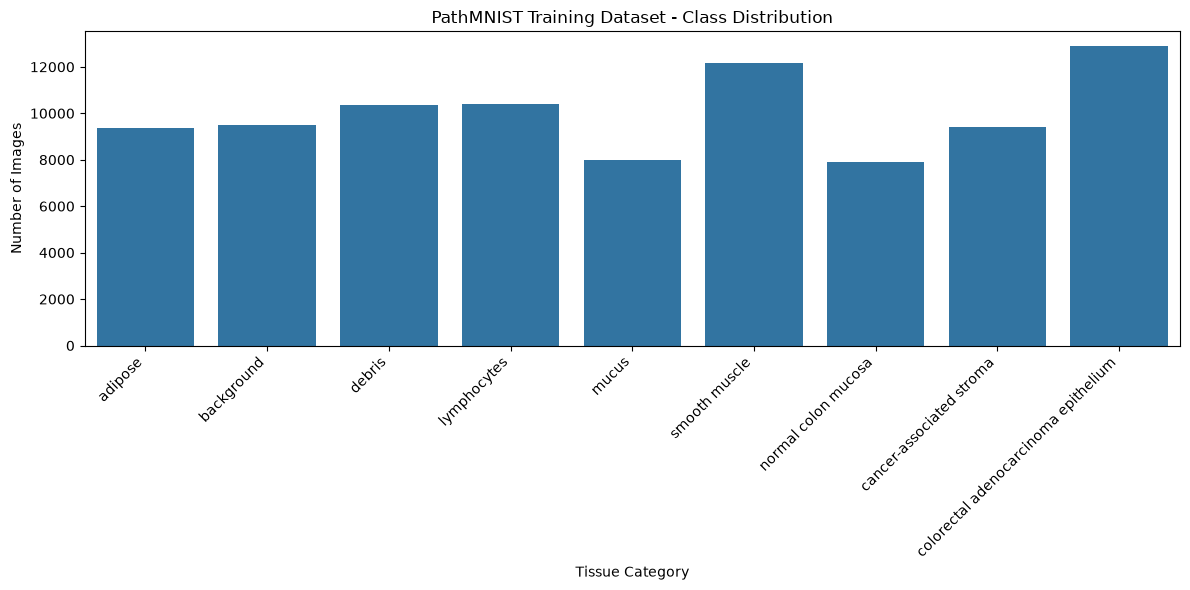

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_distribution,
    x="Category",
    y="Image Count"
)

plt.title("PathMNIST Training Dataset - Class Distribution")
plt.xlabel("Tissue Category")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

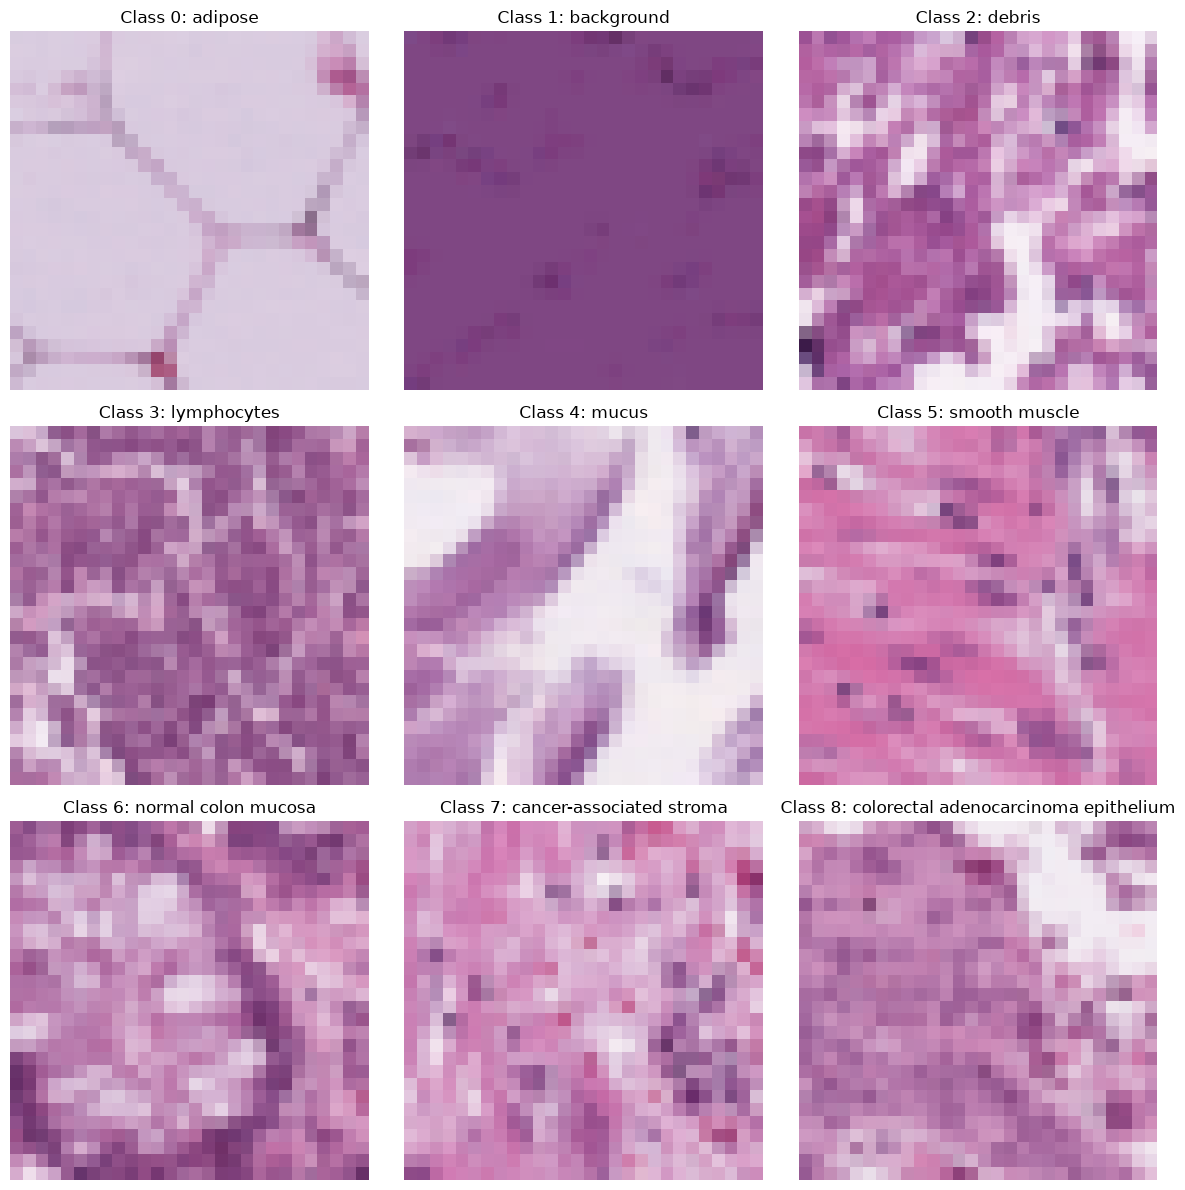

In [11]:
plt.figure(figsize=(12, 12))

for class_id in range(9):

    # Find image indices belonging to this class
    indices = np.where(flat_labels == class_id)[0]

    # Select one random image
    sample_index = np.random.choice(indices)

    image = images[sample_index]

    plt.subplot(3, 3, class_id + 1)

    plt.imshow(image)

    plt.title(
        f"Class {class_id}: {class_names[class_id]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()
